# Cylindrical refolded isocline — data, fold axis and truth

The refolded isoclinal fold of the ImplicitBenchmark, in 3-D. The 2-D fits elsewhere use the
projection of this dataset onto the fold profile; the data are 3-D, scattered over about 830 m
along the hinge. The two folds share their hinge (type 3 interference), so the fold is
cylindrical, and the bedding normals say so: they all lie in one plane, normal to *y*.

This notebook reads the raw files, decides the fold axis from the bedding, sets the modelling
frame and the evaluation box, and orders the dense contacts into the truth. It fits nothing.

| next | reads | does |
|---|---|---|
| `07b_cylindrical_isocline_ldi` | `data/processed/` | the LDI fit, cylindrical about the hinge |
| `07c_cylindrical_isocline_surfe` | `data/processed/`, `results/inputs.npz` from 07b | the Surfe fit (`ANISOTROPY` sets the range ratio along the hinge) |
| `07d_cylindrical_isocline_meshes` | `results/` | the LDI and truth surfaces |
| `07f_cylindrical_isocline_figures` | `results/` | the figures |

**Data** (`data/raw/`, as given):

- `refolded_isocline_contacts.csv`: 103 contacts on three horizons (`X`, `Y`, `Z`, `Level`);
- `refolded_isocline_orientations.csv`: 56 bedding readings (`X`, `Y`, `Z`, `nx`, `ny`, `nz`),
  the normal pointing to younger beds;
- `refolded_isocline_dense_contacts.csv`, `refolded_isocline_dense_orientations.csv`: the
  same horizons densely sampled, 400 contacts each, on the fold profile (`X`, `Z`). Every
  sparse contact is one of them. Here they are the **truth**: the fold is cylindrical, so the
  dense profile swept along the hinge is the true surface.

**Outputs.** `data/processed/` (see **Save**), read by the other notebooks through
`isocline_inputs.py`.

## Setup

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

import sys
sys.path.insert(0, str(Path("..").resolve()))  # publication/: figstyle, diagnostics, exploded3d
import figstyle
import diagnostics
import isocline_inputs
figstyle.apply()

RAW_DIR = Path("data/raw")
OUT_DIR = isocline_inputs.PROCESSED_DIR
OUT_DIR.mkdir(parents=True, exist_ok=True)

## Contacts and bedding

`LEVELS` lists the horizons youngest first. The bedding normals point to younger beds, and
the 2-D fit's restored level increases along them from level 0 to level 100, so level 100 is
the youngest. (The younger-over-older pairs in 07b follow this order.) `DROP_LEVEL0_LAST`
drops the last contact of level 0 (a point on the bottom edge of the box), as the 2-D fits
do; `False` keeps all 103. The modelling frame is centred on the centroid of
the contacts and bedding, as in 2-D, so the Fourier features stay well conditioned in
`float32`.

In [2]:
LEVELS = (100.0, 50.0, 0.0)            # young -> old
DROP_LEVEL0_LAST = True                # as in the 2-D fits

contacts = pd.read_csv(RAW_DIR / "refolded_isocline_contacts.csv")
ori = pd.read_csv(RAW_DIR / "refolded_isocline_orientations.csv")
horizons = [contacts.loc[np.isclose(contacts["Level"], lev), ["X", "Y", "Z"]].to_numpy(float) for lev in LEVELS]
if DROP_LEVEL0_LAST:
    horizons[LEVELS.index(0.0)] = horizons[LEVELS.index(0.0)][:-1]
horizon_names = [f"level {lev:.0f}" for lev in LEVELS]
gp = ori[["X", "Y", "Z"]].to_numpy(float)
gv = ori[["nx", "ny", "nz"]].to_numpy(float)
gv /= np.linalg.norm(gv, axis=1, keepdims=True)

origin = np.vstack([*horizons, gp]).mean(axis=0)
horizons = [h - origin for h in horizons]
gp = gp - origin
for name, h in zip(horizon_names, horizons):
    print(f"{name}: {len(h)} contacts, y {h[:, 1].min():.0f} to {h[:, 1].max():.0f} m, "
          f"{len(np.unique(h[:, 1]))} distinct y")
print(f"{len(gp)} bedding readings | origin (file frame) {origin.round(2)}")

level 100: 40 contacts, y -370 to 430 m, 34 distinct y
level 50: 28 contacts, y -301 to 462 m, 24 distinct y
level 0: 34 contacts, y -359 to 406 m, 28 distinct y
56 bedding readings | origin (file frame) [-43.23 586.4   99.38]


## The fold axis

The π-axis: the direction the bedding normals are most nearly perpendicular to (the
eigenvector of $\sum n n^T$ with the smallest eigenvalue). The ratio of the smallest
eigenvalue to the others says how cylindrical the bedding is (0: every normal is in one
plane). The equal-area net (lower hemisphere) shows the poles, the π-girdle and the axis;
trends are measured from +*y* towards +*x*.

hinge [ 0.  1. -0.]: trend 0.0°, plunge 0.00°, 0.0000° from y
eigenvalues [0.     0.4636 0.5364] (smallest / largest 1.38e-16)


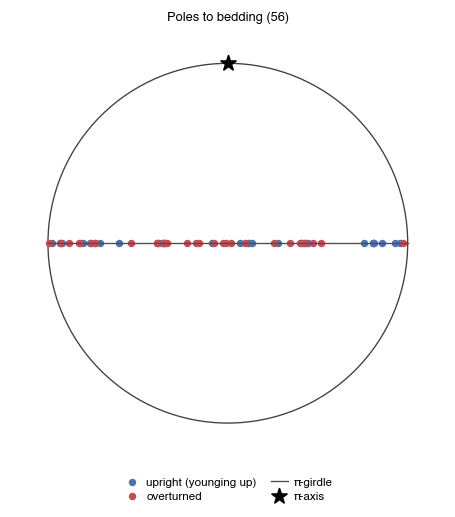

In [3]:
evals, evecs = np.linalg.eigh(gv.T @ gv / len(gv))
hinge = evecs[:, 0] * np.sign(evecs[1, 0] or 1.0)          # pointing along +y
u_ax = np.array([1.0, 0.0, 0.0]) - hinge[0] * hinge         # profile axes: u along x, w along z
u_ax /= np.linalg.norm(u_ax)
w_ax = np.cross(u_ax, hinge)
angle_to_y = float(np.degrees(np.arccos(abs(hinge[1]))))
low = hinge if hinge[2] <= 0 else -hinge
trend = float(np.degrees(np.arctan2(low[0], low[1])) % 360.0)
plunge = float(np.degrees(np.arcsin(-low[2])))
print(f"hinge {hinge.round(6)}: trend {trend:.1f}°, plunge {plunge:.2f}°, {angle_to_y:.4f}° from y")
print(f"eigenvalues {evals.round(4)} (smallest / largest {evals[0] / evals[2]:.2e})")
assert angle_to_y < 1.0, "the truth and the section measures assume a hinge along y"

fig, ax = plt.subplots(figsize=(4.2, 4.2), constrained_layout=True)
ax.set_aspect("equal"); ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2); ax.set_axis_off()
ax.add_patch(Circle((0, 0), 1.0, fill=False, edgecolor="0.25", lw=0.8))
poles = np.where(gv[:, 2:3] > 0, -gv, gv)                   # lower hemisphere
xy = diagnostics._schmidt_xy(poles)
upright = gv[:, 2] > 0
ax.scatter(*xy[upright].T, s=12, color="#4C72B0", label="upright (younging up)")
ax.scatter(*xy[~upright].T, s=12, color="#C44E52", label="overturned")
t = np.linspace(0.0, np.pi, 181)[:, None]
a_ = np.cross(hinge, [0.0, 0.0, 1.0]); a_ /= np.linalg.norm(a_)
b_ = np.cross(hinge, a_); b_ = b_ if b_[2] <= 0 else -b_
ax.plot(*diagnostics._schmidt_xy(np.cos(t) * a_ + np.sin(t) * b_).T, color="0.3", lw=0.8, label="π-girdle")
ax.scatter(*diagnostics._schmidt_xy(low[None]).T, marker="*", s=90, color="k", zorder=5, label="π-axis")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=7)
ax.set_title(f"Poles to bedding ({len(gv)})")
plt.show()

## The truth

The dense contacts are a sample of each horizon on the fold profile, in no particular order.
They are moved into the modelling frame and, for the 3-D figures, ordered into polylines by
a nearest-neighbour walk (`isocline_inputs.chain`) that ends a line at any gap longer than
`MAX_JUMP`. The dense set is the profile projection of the fold, so its `(X, Z)` are the
profile coordinates `(u, w)` (the hinge is along *y*). The plot checks the ordering: each
horizon should be one or a few long lines, with no chord jumping between limbs, and every
sparse contact on its line.

level 100: 400 truth points (median spacing 7.1 m) -> 1 polylines, lengths [400]
level 50: 400 truth points (median spacing 8.5 m) -> 1 polylines, lengths [400]
level 0: 400 truth points (median spacing 9.5 m) -> 1 polylines, lengths [400]


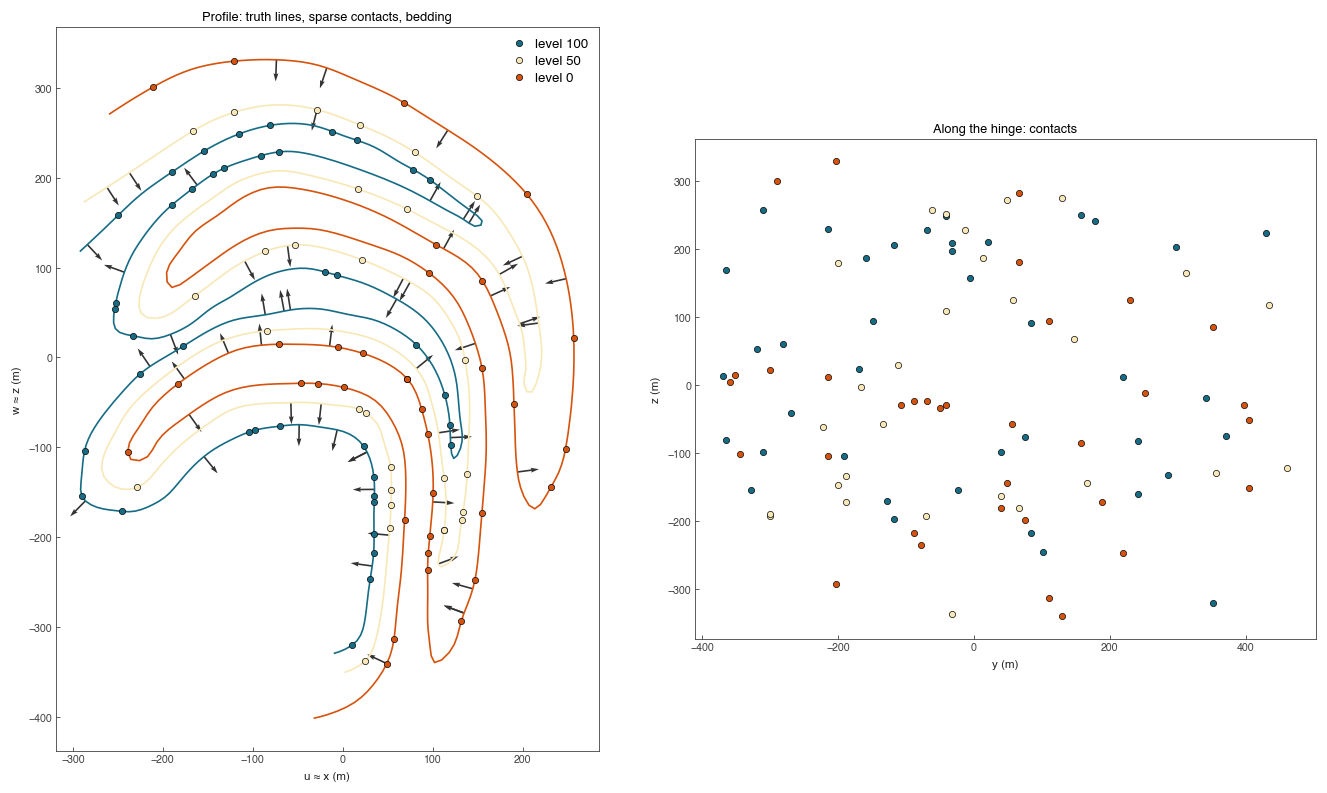

In [4]:
MAX_JUMP = 40.0                         # m, a longer gap ends a truth polyline

dense = pd.read_csv(RAW_DIR / "refolded_isocline_dense_contacts.csv")
truth_points = [dense.loc[np.isclose(dense["Level"], lev), ["X", "Z"]].to_numpy(float) - origin[[0, 2]]
                for lev in LEVELS]
truth_lines = [isocline_inputs.chain(p, MAX_JUMP) for p in truth_points]
for name, p, lines in zip(horizon_names, truth_points, truth_lines):
    gap = np.median(isocline_inputs.cKDTree(p).query(p, k=2)[0][:, 1])
    print(f"{name}: {len(p)} truth points (median spacing {gap:.1f} m) -> {len(lines)} polylines, "
          f"lengths {[len(l) for l in lines]}")

colors = [figstyle.ramp()(t) for t in np.linspace(0.9, 0.1, len(LEVELS))]
fig, axs = plt.subplots(1, 2, figsize=(11, 6.5), constrained_layout=True)
for p, lines, h, c, name in zip(truth_points, truth_lines, horizons, colors, horizon_names):
    for l in lines:
        axs[0].plot(*l.T, color=c, lw=1.0)
    axs[0].scatter(*isocline_inputs.to_profile(h, u_ax, w_ax).T, s=14, color=c, edgecolors="k", linewidths=0.4,
                   zorder=5, label=name)
    axs[1].scatter(h[:, 1], h[:, 2], s=14, color=c, edgecolors="k", linewidths=0.4, label=name)
axs[0].quiver(*isocline_inputs.to_profile(gp, u_ax, w_ax).T, gv @ u_ax, gv @ w_ax, color="0.2", width=0.003,
              scale=25)
axs[0].set(title="Profile: truth lines, sparse contacts, bedding", xlabel="u ≈ x (m)", ylabel="w ≈ z (m)", aspect="equal")
axs[1].set(title="Along the hinge: contacts", xlabel="y (m)", ylabel="z (m)", aspect="equal")
axs[0].legend(frameon=False, fontsize=8)
plt.show()

## Evaluation box

The 2-D benchmark box on the profile (`BOX_U` × `BOX_W`, centred on the data as in 2-D) swept
along the hinge over the data's extent plus `PAD_Y` at each end. Every fit is evaluated, and
every figure drawn, inside it.

In [5]:
BOX_U, BOX_W = 600.0, 800.0             # m, profile size (the 2-D box)
PAD_Y = 50.0                            # m, past the data at each end along the hinge

y_all = np.vstack([*horizons, gp])[:, 1]
box = np.array([[-BOX_U / 2, y_all.min() - PAD_Y, -BOX_W / 2],
                [BOX_U / 2, y_all.max() + PAD_Y, BOX_W / 2]])
inside = np.all((np.vstack([*horizons, gp]) >= box[0]) & (np.vstack([*horizons, gp]) <= box[1]), axis=1)
print("box (modelling frame):", box.round(1).tolist(), "| size", np.ptp(box, axis=0).round(0),
      f"| data inside: {inside.mean():.0%}")

box (modelling frame): [[-300.0, -419.9, -400.0], [300.0, 511.6, 400.0]] | size [600. 932. 800.] | data inside: 100%


## Save

`data/processed/isocline_processed.npz` (the frame, the data, the axis, the truth and the box)
and `settings.json` (the choices made here).

In [6]:
lines_packed = {}
for h, lines in enumerate(truth_lines):
    xyz, off = isocline_inputs.pack(lines)
    lines_packed[f"truth_lines_{h}"], lines_packed[f"truth_offsets_{h}"] = xyz, off
np.savez_compressed(
    OUT_DIR / "isocline_processed.npz",
    origin=origin, horizon_names=np.asarray(horizon_names), levels=np.asarray(LEVELS),
    **{f"horizon_{h}": x for h, x in enumerate(horizons)},
    gp=gp, gv=gv, hinge=hinge, u_ax=u_ax, w_ax=w_ax, box=box,
    **{f"truth_points_{h}": p for h, p in enumerate(truth_points)}, **lines_packed,
)
(OUT_DIR / "settings.json").write_text(json.dumps(dict(
    levels=list(LEVELS), drop_level0_last=DROP_LEVEL0_LAST, max_jump=MAX_JUMP,
    box_u=BOX_U, box_w=BOX_W, pad_y=PAD_Y,
    hinge_trend_plunge=[trend, plunge], hinge_angle_to_y_deg=angle_to_y, pi_eigenvalues=evals.tolist(),
), indent=2))
print("wrote", OUT_DIR / "isocline_processed.npz", "and settings.json")

wrote data/processed/isocline_processed.npz and settings.json
